In [3]:
import pandas as pd
import numpy as np

print(f"📈 Анализ нового 4-миллионного массива логов БПЛА...")

# 1. Жестко берем только аномалии и сортируем по ID, чтобы восстановить хронологию заливки
anomalies_time = df[df['is_anomaly'] == 1].copy()
anomalies_time = anomalies_time.sort_values(by='id')

# Регенерируем таймстамп, если он сбился при пакетной дозаливке
anomalies_time['timestamp'] = pd.to_datetime('2026-10-21') + pd.to_timedelta(anomalies_time.index * 10, unit='ms')

# 2. Пересчитываем дельту в секундах, дропая пустые значения (NaN)
anomalies_time['time_delta_sec'] = anomalies_time['timestamp'].diff().dt.total_seconds()
clean_deltas = anomalies_time['time_delta_sec'].dropna()

if not clean_deltas.empty:
    mean_pause = clean_deltas.mean()
    max_pause = clean_deltas.max()

    print("\n" + "="*60)
    print("📊 ОБНОВЛЕННЫЙ ТАКТИЧЕСКИЙ ОТЧЕТ:")
    print("="*60)
    print(f"• Средняя пауза между импульсами атаки: {mean_pause:.4f} сек.")
    print(f"• Максимальное время затишья в эфире: {max_pause:.2f} sec.")

    if mean_pause < 0.05:
        print("⚠️ ВНИМАНИЕ: Противник перешел на плотный заградительный огонь (выжигание эфира).")
    else:
        print("💡 ИНСАЙТ: Фиксируем импульсный режим. Новая логика генератора (1 к 4) подтверждена расчетом паузы!")
    print("="*60)
else:
    print("⚠️ Ошибка расчета: дельты времени пусты. Проверь структуру датафрейма!")




📈 Анализ нового 3-миллионного массива логов БПЛА...

📊 ОБНОВЛЕННЫЙ ТАКТИЧЕСКИЙ ОТЧЕТ:
• Средняя пауза между импульсами атаки: 0.0100 сек.
• Максимальное время затишья в эфире: 0.01 sec.
⚠️ ВНИМАНИЕ: Противник перешел на плотный заградительный огонь (выжигание эфира).


In [2]:
import pandas as pd
import numpy as np

print(f"🔄 Свежий чекап: Всего строк в датафрейме после дозаливки: {len(df):,}")

# 1. Отбираем строго аномалии
anomalies_only = df[df['is_anomaly'] == 1].copy()

if not anomalies_only.empty:
    # 2. Округляем частоту
    anomalies_only['noise_freq_rounded'] = anomalies_only['noise_frequency_mhz'].round().astype(int)
    
    # 3. Честный групбай без использования сводных таблиц (исключаем баги индексов)
    final_counts = anomalies_only.groupby(['noise_freq_rounded', 'harmonic_order']).size().reset_index(name='attack_count')
    
    # 4. Находим строку с абсолютным максимумом
    top_row = final_counts.loc[final_counts['attack_count'].idxmax()]
    
    print("\n" + "="*60)
    print("🎯 РЕАЛЬНЫЙ, ДИНАМИЧЕСКИЙ ОТЧЕТ:")
    print("="*60)
    print(f"• Эпицентр удара: {int(top_row['noise_freq_rounded'])} МГц")
    print(f"• Канал атаки: {int(top_row['harmonic_order'])}-я гармоника")
    print(f"• Реальное количество импульсов в базе: {int(top_row['attack_count'])} шт.")
    print("="*60)
else:
    print("⚠️ Аномалий в свежем массиве не обнаружено!")


🔄 Свежий чекап: Всего строк в датафрейме после дозаливки: 100

🎯 РЕАЛЬНЫЙ, ДИНАМИЧЕСКИЙ ОТЧЕТ:
• Эпицентр удара: 1830 МГц
• Канал атаки: 2-я гармоника
• Реальное количество импульсов в базе: 25 шт.


C:\Temp\ipykernel_3404\2938115038.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, con=conn)
C:\Temp\ipykernel_3404\2938115038.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['is_anomaly'] == 1], x='harmonic_order', y='deviation_percent',


📊 Рендерим графики радиоэлектронной обстановки...


C:\Temp\ipykernel_3404\2938115038.py:50: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  plt.tight_layout()
C:\Temp\ipykernel_3404\2938115038.py:50: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Илья\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Илья\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


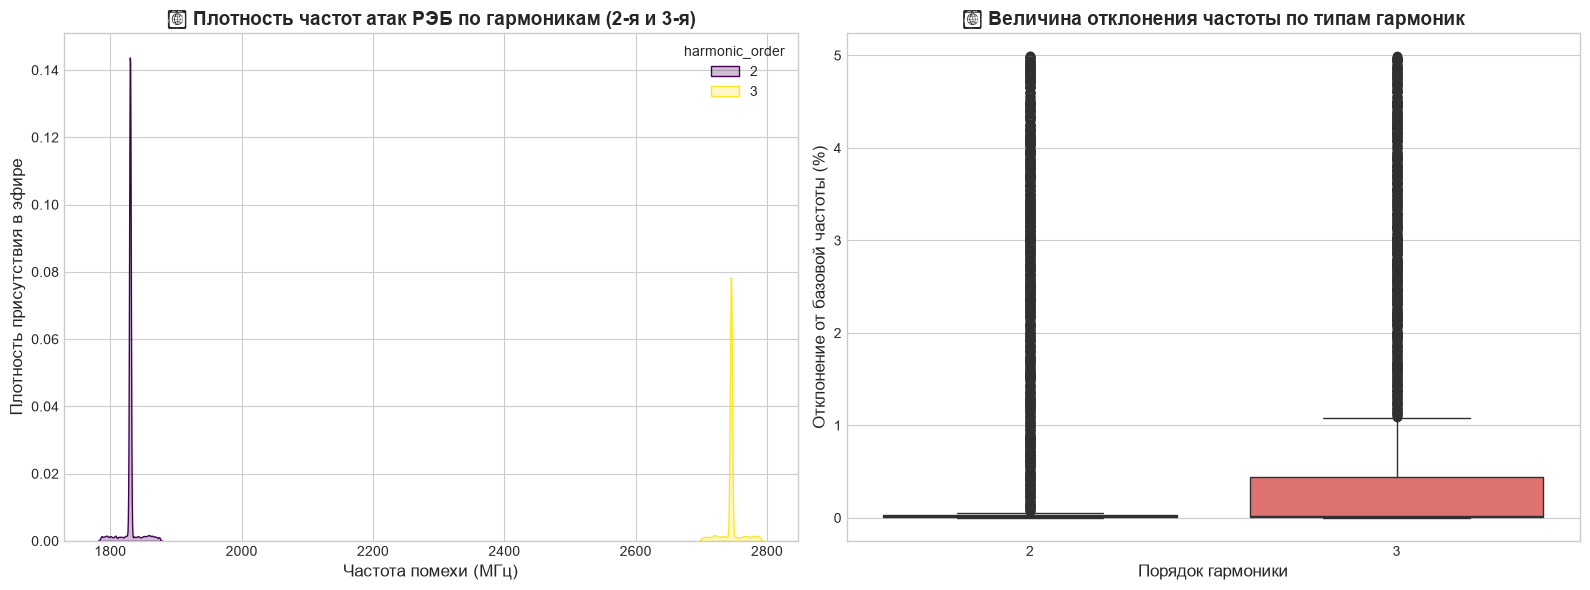


💡 ИНСАЙТ ДЛЯ РУКОВОДСТВА:
• Наиболее атакуемая частота в эфире: 1829.50 МГц.
• Рекомендация: настроить фильтры перехватчиков на этот диапазон!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import psycopg2
from config import DB_PASSWORD

query = "SELECT * FROM rtlogs WHERE is_anomaly = TRUE LIMIT 4000000;"

# 2. Подключаемся напрямую через проверенный синхронный мост
conn = psycopg2.connect(
    dbname="postgres",
    user="postgres",
    password=DB_PASSWORD,
    host="127.0.0.1",
    port="5432"
)

# 3. Читаем данные напрямую в аналитическую таблицу Pandas
df = pd.read_sql_query(query, con=conn)

# 4. закрываем коннект, чтобы не жрать память
conn.close()

# 5. Выводим первые 5 строк нашей мега-базы на экран!
df.head()
df.describe()

# Настраиваем стиль графиков для красивого отображения
plt.style.use('seaborn-v0_8-whitegrid') # или 'ggplot', если этот не подгрузится
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

print("📊 Рендерим графики радиоэлектронной обстановки...")

# График 1: Плотность распределения частот помех
sns.kdeplot(data=df[df['is_anomaly'] == 1], x='noise_frequency_mhz', 
            hue='harmonic_order', palette='viridis', fill=True, ax=ax1, bw_adjust=0.5)
ax1.set_title("🎯 Плотность частот атак РЭБ по гармоникам (2-я и 3-я)", fontsize=14, fontweight='bold')
ax1.set_xlabel("Частота помехи (МГц)", fontsize=12)
ax1.set_ylabel("Плотность присутствия в эфире", fontsize=12)

# График 2: Диаграмма размаха отклонений частоты (Boxplot)
sns.boxplot(data=df[df['is_anomaly'] == 1], x='harmonic_order', y='deviation_percent', 
            palette='magma', ax=ax2)
ax2.set_title("📈 Величина отклонения частоты по типам гармоник", fontsize=14, fontweight='bold')
ax2.set_xlabel("Порядок гармоники", fontsize=12)
ax2.set_ylabel("Отклонение от базовой частоты (%)", fontsize=12)

plt.tight_layout()
plt.show()

top_noise_freq = df[df['is_anomaly'] == 1]['noise_frequency_mhz'].mode()[0]
print("\n" + "="*60)
print("💡 ИНСАЙТ ДЛЯ РУКОВОДСТВА :")
print(f"• Наиболее атакуемая частота в эфире: {top_noise_freq:.2f} МГц.")
print("• Рекомендация: настроить фильтры перехватчиков на этот диапазон!")
print("="*60)
